# 02 — Extração completa de features (851 gravações)

Engenharia de features para classificação multiclasse Healthy / COPD / URTI:

- **MFCC** (13 coef.) — mean + std
- **Delta-MFCC** (1ª derivada) — mean
- **Delta²-MFCC** (2ª derivada) — mean
- **Chroma STFT** (12 bins) — mean
- **Spectral contrast** (7 bandas) — mean
- **Features espectrais**: centroide, rolloff, bandwidth, flatness
- **Energia**: RMS, ZCR

Total: **78 features** por gravação. Persistido em `data/processed/features.csv`.

In [1]:
import sys, time
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

from src import config, metadata, features

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 30)

## 1. Carregar metadata filtrada (3 classes)

In [2]:
df = metadata.build_recordings_dataframe()
df = metadata.filter_target_classes(df)
df = metadata.add_target_labels(df)
print(f'Gravações: {len(df)} | Pacientes: {df["patient_id"].nunique()}')
df['label_multi'].value_counts()

Gravações: 851 | Pacientes: 104


label_multi
COPD       793
Healthy     35
URTI        23
Name: count, dtype: int64

## 2. Extração de features

Rodamos `features.extract_from_file` em todas as 851 gravações. Tempo esperado: ~3–8 min dependendo da máquina. As features são salvas em CSV para reuso nos próximos notebooks.

In [3]:
FEATURES_CSV = config.PROCESSED_DIR / 'features.csv'

if FEATURES_CSV.exists():
    print(f'Carregando features cacheadas de {FEATURES_CSV}')
    feats_df = pd.read_csv(FEATURES_CSV)
else:
    t0 = time.time()
    rows = []
    for _, r in tqdm(df.iterrows(), total=len(df), desc='Extraindo'):
        f = features.extract_from_file(r['wav_path'])
        f['filename'] = r['filename']
        f['patient_id'] = r['patient_id']
        f['equipment'] = r['equipment']
        f['chest_location'] = r['chest_location']
        f['label_multi'] = r['label_multi']
        f['label_binary'] = r['label_binary']
        rows.append(f)
    feats_df = pd.DataFrame(rows)
    feats_df.to_csv(FEATURES_CSV, index=False)
    print(f'Extraído em {time.time()-t0:.1f}s | shape: {feats_df.shape}')
    print(f'Salvo em: {FEATURES_CSV}')

feats_df.head()

Carregando features cacheadas de C:\Users\leodg\projeto_cdg1.1\data\processed\features.csv


,mfcc1_mean,mfcc1_std,mfcc1_d_mean,mfcc1_d2_mean,mfcc2_mean,mfcc2_std,mfcc2_d_mean,mfcc2_d2_mean,mfcc3_mean,mfcc3_std,mfcc3_d_mean,mfcc3_d2_mean,mfcc4_mean,mfcc4_std,mfcc4_d_mean,...,contrast6_mean,contrast7_mean,zcr_mean,rms_mean,centroid_mean,rolloff_mean,bandwidth_mean,flatness_mean,duration_s,filename,patient_id,equipment,chest_location,label_multi,label_binary
0,-528.425232,28.375187,-0.017549,0.236458,104.517365,24.670374,0.004808,0.036089,69.907585,15.964994,0.022881,-0.023820,42.572124,12.203480,0.010277,...,13.516793,39.793539,0.002117,0.056384,129.340184,102.857267,647.469627,6.019614e-06,20.000000,101_1b1_Al_sc_Meditron.wav,101,WelchAllyn Meditron,Anterior left,URTI,Disease
1,-582.504700,24.621038,0.072162,0.178364,95.394691,22.027939,0.062635,0.011000,57.402180,11.650138,0.012487,-0.022805,31.435291,10.061437,-0.029636,...,13.504806,41.088305,0.001885,0.034013,156.085273,81.761223,816.768435,9.156409e-06,20.000000,101_1b1_Pr_sc_Meditron.wav,101,WelchAllyn Meditron,Posterior right,URTI,Disease
2,-596.806091,22.520979,-0.017105,0.115947,116.009735,24.727230,-0.043550,0.042133,60.592537,16.616146,0.037273,-0.020620,25.570189,10.733197,0.062602,...,13.547150,41.850116,0.002278,0.022135,192.965319,138.804226,870.775844,1.028045e-05,20.000000,102_1b1_Ar_sc_Meditron.wav,102,WelchAllyn Meditron,Anterior right,Healthy,Healthy
3,-441.498169,40.611320,-0.063146,0.015621,100.994278,47.306488,-0.088244,0.009985,74.064339,24.414709,-0.075454,-0.012154,43.248154,9.672344,-0.040045,...,14.275840,14.171768,0.006757,0.069231,115.155966,221.921254,152.844687,2.126648e-08,15.856009,104_1b1_Al_sc_Litt3200.wav,104,Littmann 3200 Electronic,Anterior left,COPD,Disease
4,-443.037079,40.578865,0.003159,0.016769,106.827316,45.878059,0.013043,0.021375,74.783844,21.028540,0.030220,0.014744,40.041946,12.295695,0.038613,...,12.361837,12.276100,0.007559,0.048244,140.613149,287.220102,181.379660,9.291450e-09,25.584036,104_1b1_Ar_sc_Litt3200.wav,104,Littmann 3200 Electronic,Anterior right,COPD,Disease


## 3. Sanity check — sem NaN / Inf

In [4]:
num_cols = feats_df.select_dtypes(include='number').columns
n_nan = feats_df[num_cols].isna().sum().sum()
n_inf = np.isinf(feats_df[num_cols]).sum().sum()
print(f'NaN: {n_nan} | Inf: {n_inf}')
print(f'Shape final: {feats_df.shape}')
feats_df.describe().T.head(10)

NaN: 0 | Inf: 0
Shape final: (851, 84)


,count,mean,std,min,25%,50%,75%,max
mfcc1_mean,851.0,-369.401529,98.709969,-717.357910,-430.781998,-354.496796,-296.351089,-135.851807
mfcc1_std,851.0,28.232996,13.004358,7.064713,18.834991,25.239124,34.174833,113.784416
mfcc1_d_mean,851.0,0.143850,0.130298,-0.327868,0.046691,0.147884,0.233209,0.617756
mfcc1_d2_mean,851.0,-0.043198,0.088639,-0.252838,-0.108335,-0.054637,0.006158,0.285473
mfcc2_mean,851.0,113.644212,27.007466,43.368004,98.093838,111.255737,130.121216,217.013504
mfcc2_std,851.0,23.140858,9.804167,6.535458,15.617049,21.448042,29.434330,54.290237
mfcc2_d_mean,851.0,0.095586,0.069521,-0.359624,0.049100,0.112525,0.138546,0.301898
mfcc2_d2_mean,851.0,-0.040822,0.037415,-0.169622,-0.063337,-0.052559,-0.025392,0.114048
mfcc3_mean,851.0,51.795919,18.208146,-50.699837,42.962126,52.940437,63.383743,103.954041
mfcc3_std,851.0,12.675403,5.322226,3.138749,9.080492,11.385627,15.041224,48.951347


## 4. Distribuição de features por classe

Visualização de algumas features-chave para confirmar separabilidade — se classes se sobrepõem totalmente em todas as dimensões, modelos clássicos vão sofrer.

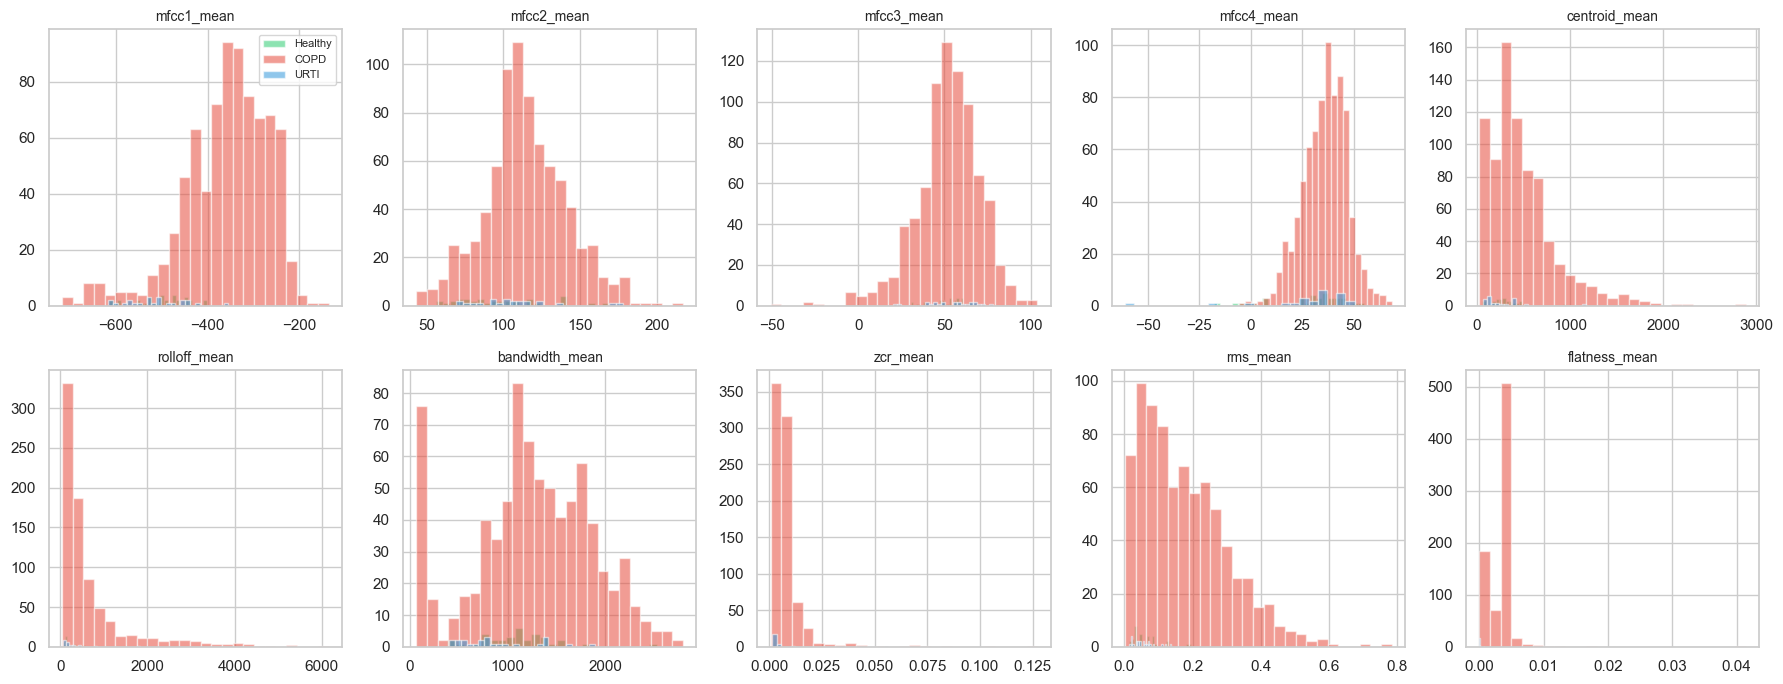

In [5]:
key_feats = ['mfcc1_mean', 'mfcc2_mean', 'mfcc3_mean', 'mfcc4_mean',
             'centroid_mean', 'rolloff_mean', 'bandwidth_mean',
             'zcr_mean', 'rms_mean', 'flatness_mean']
fig, axes = plt.subplots(2, 5, figsize=(18, 7))
for ax, col in zip(axes.flat, key_feats):
    for cls, color in zip(['Healthy', 'COPD', 'URTI'], ['#2ecc71', '#e74c3c', '#3498db']):
        vals = feats_df[feats_df['label_multi'] == cls][col]
        ax.hist(vals, bins=25, alpha=0.55, label=cls, color=color)
    ax.set_title(col, fontsize=10)
axes[0, 0].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 5. Correlação entre features

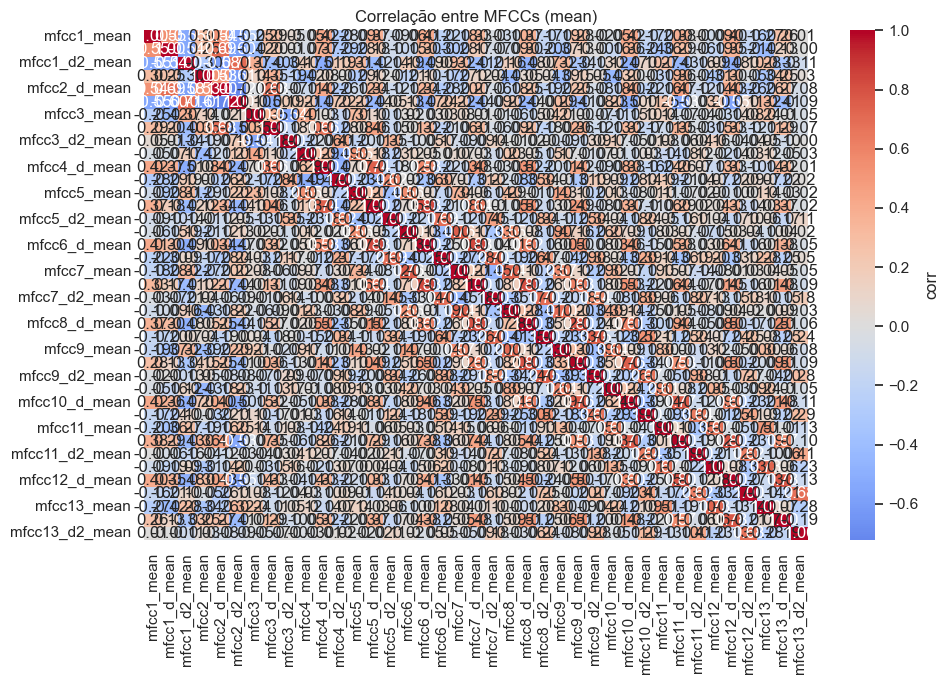

In [6]:
mfcc_cols = [c for c in feats_df.columns if c.startswith('mfcc') and c.endswith('_mean')]
corr = feats_df[mfcc_cols].corr()
plt.figure(figsize=(10, 7))
sns.heatmap(corr, cmap='coolwarm', center=0, annot=True, fmt='.2f',
            cbar_kws={'label': 'corr'})
plt.title('Correlação entre MFCCs (mean)')
plt.tight_layout(); plt.show()

## Próximo passo

**Notebook 03** — treinar XGBoost, LDA, Regressão Logística e KNN sobre `features.csv` com `StratifiedGroupKFold(groups=patient_id)` e matriz de confusão a nível de paciente.